# Breast Cancer Survival Prediction
## Notebook 2: Classification of Mortality Status

Author: Armaan Khan

In this notebook I build three models to predict whether a patient died: Logistic Regression (LR), a Multilayer Perceptron (MLP) and a Decision Tree Classifier (DT). I then evaluate them, choose the best one and tune its hyperparameters to improve it. I use the cleaned dataset from Notebook 1.

The main challenge is that only 15% of the patients died. A model can look accurate by predicting that every patient is alive, so it is important to judge the models with the right metrics.

In [1]:
# Importing the libraries needed for this notebook
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, classification_report, ConfusionMatrixDisplay)

# Using the same random state throughout so the results are the same every time the code is run
RANDOM_STATE = 23

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Loading the cleaned dataset and declaring the features

In [2]:
# Loading the cleaned dataset from Notebook 1
df = pd.read_csv("data/cleaned_breast_cancer.csv")

# Displaying the first 5 rows to familiarise myself with it
df.head()

,Age,T_Stage,N_Stage,Grade,A_Stage,Tumor_Size,Estrogen_Status,Progesterone_Status,Regional_Node_Examined,Regional_Node_Positive,Survival_Months,Died
0,68.0,1,1,3,0,4.0,1,1,24.0,1.0,60,0
1,50.0,2,2,2,0,35.0,1,1,14.0,5.0,62,0
2,58.0,3,3,2,0,63.0,1,1,14.0,7.0,75,0
3,58.0,1,1,3,0,18.0,1,1,2.0,1.0,84,0
4,47.0,2,1,3,0,41.0,1,1,3.0,1.0,50,0


In [3]:
# Declaring the input features (X) and the target output (y)
feature_cols = ["Age", "T_Stage", "N_Stage", "A_Stage", "Grade", "Tumor_Size", "Estrogen_Status",
                "Progesterone_Status", "Regional_Node_Examined", "Regional_Node_Positive"]

X = df[feature_cols]
y = df["Died"]

# Printing the feature names and the shape of the input features and the target
print(feature_cols)
print(X.shape)
print(y.shape)

['Age', 'T_Stage', 'N_Stage', 'A_Stage', 'Grade', 'Tumor_Size', 'Estrogen_Status', 'Progesterone_Status', 'Regional_Node_Examined', 'Regional_Node_Positive']
(4015, 10)
(4015,)


Survival_Months is not used as an input feature. It is only known after the outcome, and the patients who died were followed up for less time, so the model would learn that a short survival time means the patient died. That isn't really predicting anything, and is called data leakage.

## 2. The three algorithms

| Algorithm | Type | Learnable parameters | Strategic hyperparameters to tune |
|---|---|---|---|
| Logistic Regression (LR) | Parametric | Weights (one for each feature) and the intercept | C, class_weight, solver |
| Multilayer Perceptron (MLP) | Parametric | Weights and biases of every neuron | hidden_layer_sizes, activation, solver, learning_rate |
| Decision Tree Classifier (DT) | Non-parametric | The feature and threshold used at each split, and the structure of the tree | max_depth, criterion, splitter |

LR and MLP are parametric because they learn a fixed number of weights. A decision tree is non-parametric because its structure grows depending on the data.

## 3. Splitting the data into training and test sets

I use an 80:20 split, which is a common choice in machine learning. It is a trade off between giving the models enough data to learn from and keeping enough data back to test them properly. If the training set is too small the model will underfit, and if the test set is too small the evaluation will be unreliable.

Two conditions are important here:

1. **All the models are tested on the same patients.** Setting `random_state=23` means the same patients end up in the test set every time the code is run, which is essential for reproducibility and a fair comparison between the models.
2. **The ratio of alive to dead patients is the same in the training and test sets.** Using `stratify=y` does this, which is essential for an imbalanced dataset like this one. Without it, the test set could end up with too few dead patients, which would make the scores misleading.

In [4]:
# Splitting the dataset into 80% training and 20% testing subsets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

# Checking the ratio of dead patients is the same in both sets
print("Training set:", X_train.shape, f"{y_train.mean():.1%}", "died")
print("Test set:", X_test.shape, f"{y_test.mean():.1%}", "died")

Training set: (3212, 10) 15.3% died
Test set: (803, 10) 15.3% died


## 4. Building the models

Each model is built as a pipeline, so the same steps happen in the same order every time:

1. **Mean imputation** fills in the missing values with the mean of the training data
2. **StandardScaler** scales the features to the same range (only for LR and MLP, as they are sensitive to scaling, while decision trees aren't)
3. The model itself

Because the imputation and scaling are inside the pipeline, they are only fitted on the training data, so the test set doesn't leak into training.

### Logistic Regression

In [5]:
# Declaring the Logistic Regression pipeline with the default settings
lr = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),
    ("scale", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000)),
])

# Training the Logistic Regression model on the training data
lr.fit(X_train, y_train)
print("Logistic Regression trained")

Logistic Regression trained


### Multilayer Perceptron

The MLP has a lot of possible settings, so I use GridSearchCV to choose them. It tries every combination using 5-fold cross-validation on the training data only, and keeps the one with the best F1-score (the reason for using F1-score is explained in section 6).

In [6]:
# 5-fold cross-validation which keeps the ratio of alive to dead patients the same in each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Declaring the MLP pipeline
mlp_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),
    ("scale", StandardScaler()),
    ("model", MLPClassifier(max_iter=500, random_state=RANDOM_STATE)),
])

# Creating the parameter dictionary with some of the hidden layers, activations, solvers and learning rates
mlp_params = {
    "model__hidden_layer_sizes": [(50,), (50, 100)],
    "model__activation": ["relu", "tanh"],
    "model__solver": ["adam", "sgd"],
    "model__learning_rate": ["constant", "adaptive"],
}

# Applying GridSearchCV to find the best parameters for the MLP
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    mlp_grid = GridSearchCV(mlp_pipeline, mlp_params, scoring="f1", cv=cv, n_jobs=-1)
    mlp_grid.fit(X_train, y_train)

print("Best parameters:", {k.replace("model__", ""): v for k, v in mlp_grid.best_params_.items()})
mlp = mlp_grid.best_estimator_

Best parameters: {'activation': 'relu', 'hidden_layer_sizes': (50, 100), 'learning_rate': 'constant', 'solver': 'adam'}


### Decision Tree Classifier

I build a fully grown tree first, then a pruned tree with a maximum depth of 4. A fully grown tree keeps splitting until it has memorised the training data, which usually means it does much worse on new patients (overfitting).

In [7]:
# Building a fully grown decision tree
dt_full = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),
    ("model", DecisionTreeClassifier(random_state=RANDOM_STATE)),
])
dt_full.fit(X_train, y_train)

# Building a pruned decision tree with a maximum depth of 4
dt_pruned = Pipeline([
    ("impute", SimpleImputer(strategy="mean")),
    ("model", DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)),
])
dt_pruned.fit(X_train, y_train)

# Checking the depth and the training vs test accuracy of both trees
for name, tree in [("Fully grown", dt_full), ("Pruned", dt_pruned)]:
    print(f"{name} tree: depth {tree.named_steps['model'].get_depth()}, "
          f"training accuracy {tree.score(X_train, y_train):.3f}, test accuracy {tree.score(X_test, y_test):.3f}")

Fully grown tree: depth 25, training accuracy 0.999, test accuracy 0.746
Pruned tree: depth 4, training accuracy 0.856, test accuracy 0.847


The fully grown tree is 25 levels deep and gets 99.9% of the training patients right, but only 74.6% of the test patients, so it has memorised the training data (overfitting). The pruned tree's training and test accuracy are much closer (85.6% and 84.7%), which shows it generalises better to new patients.

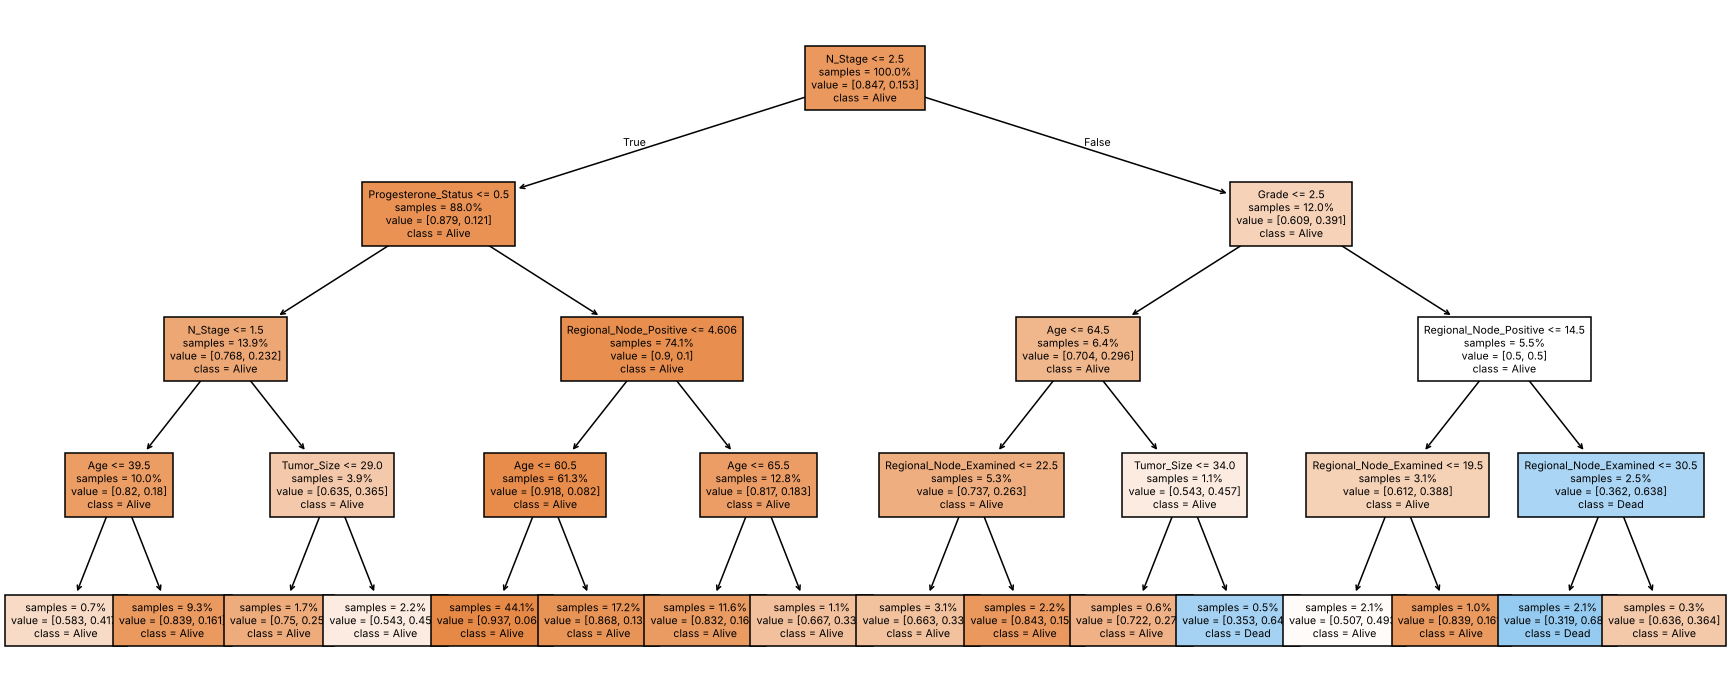

In [8]:
# Plotting the pruned decision tree
fig, ax = plt.subplots(figsize=(20, 8))
plot_tree(dt_pruned.named_steps["model"], feature_names=feature_cols, class_names=["Alive", "Dead"],
          filled=True, fontsize=7, impurity=False, proportion=True, ax=ax)
plt.savefig("images/pruned_decision_tree.png", bbox_inches="tight")
plt.show()

## 5. Evaluating the models on the test set

### Confusion matrices

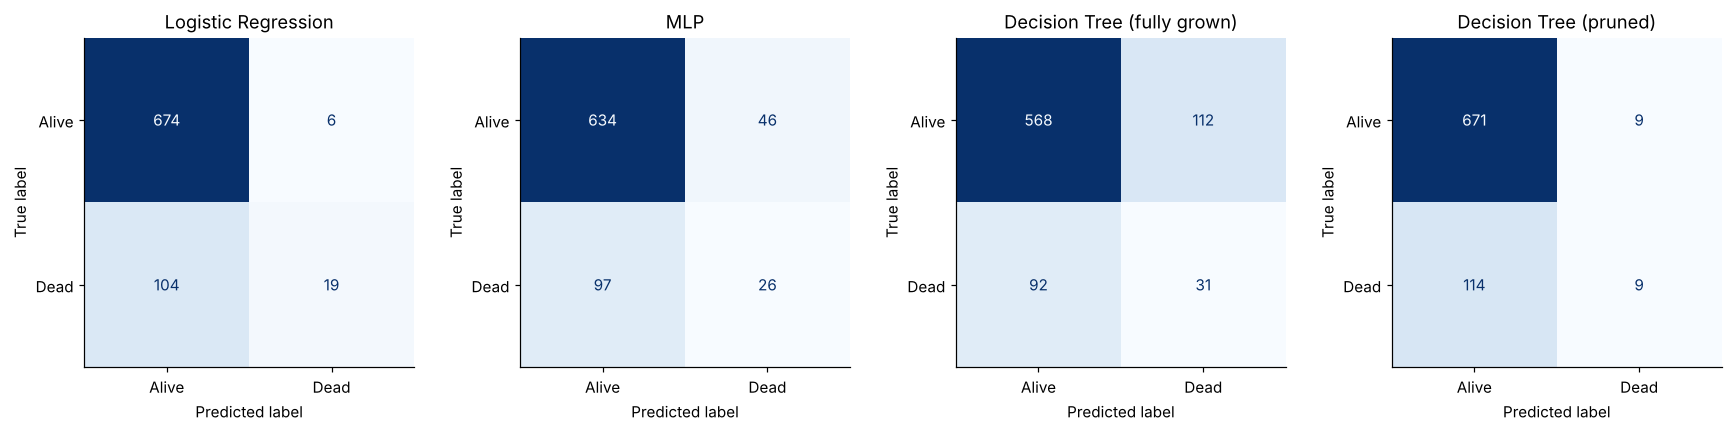

In [9]:
models = {"Logistic Regression": lr, "MLP": mlp, "Decision Tree (fully grown)": dt_full,
          "Decision Tree (pruned)": dt_pruned}

# Plotting the test confusion matrix for each model, titled with its name
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), display_labels=["Alive", "Dead"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout()
plt.show()

### Classification reports

In [10]:
# Displaying the classification report for each model
for name, model in models.items():
    print(name)
    print(classification_report(y_test, model.predict(X_test), target_names=["Alive", "Dead"]))

Logistic Regression
              precision    recall  f1-score   support

       Alive       0.87      0.99      0.92       680
        Dead       0.76      0.15      0.26       123

    accuracy                           0.86       803
   macro avg       0.81      0.57      0.59       803
weighted avg       0.85      0.86      0.82       803

MLP
              precision    recall  f1-score   support

       Alive       0.87      0.93      0.90       680
        Dead       0.36      0.21      0.27       123

    accuracy                           0.82       803
   macro avg       0.61      0.57      0.58       803
weighted avg       0.79      0.82      0.80       803

Decision Tree (fully grown)
              precision    recall  f1-score   support

       Alive       0.86      0.84      0.85       680
        Dead       0.22      0.25      0.23       123

    accuracy                           0.75       803
   macro avg       0.54      0.54      0.54       803
weighted avg       0.7

### ROC curves

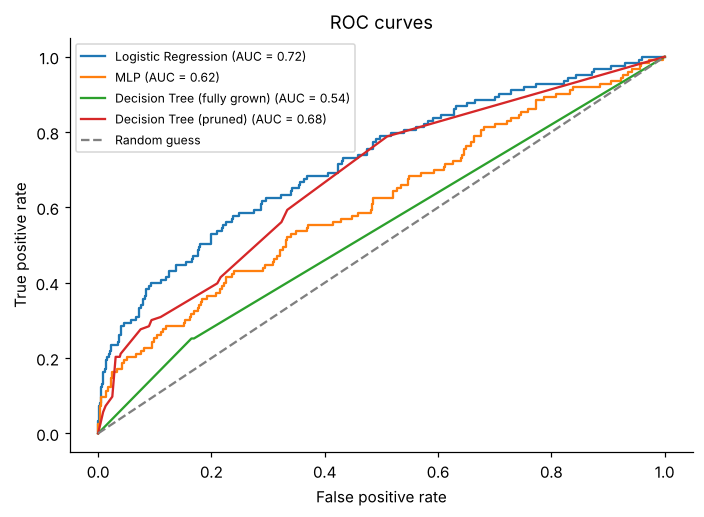

In [11]:
# Plotting the ROC curve for each model on the same graph
fig, ax = plt.subplots(figsize=(6.5, 4.8))
for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, probabilities)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, probabilities):.2f})")
ax.plot([0, 1], [0, 1], ls="--", c="grey", label="Random guess")
ax.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Choosing the evaluation metrics

The success criteria for this model is that it should find as many of the patients who died as possible, while making sure that most of the patients it predicts as dead really did die, so there aren't too many false alarms. All the scores below are for the dead class.

| Metric | Use or don't use | Justification |
|---|---|---|
| Accuracy | Don't use | Accuracy can be misleading if a dataset is imbalanced. In this dataset a large majority of the patients were alive (85%), so a model could simply predict the majority class and still look accurate, without finding a single patient who died. |
| Precision | Use | Precision measures how many of the patients predicted as dead actually died. This directly matches the part of the success criteria about avoiding false alarms. |
| Recall | Don't use on its own | Recall measures how many of the patients who died were found by the model. It ignores false positives, so a model that predicted every patient as dead would get a perfect recall while being useless. |
| F1-score | Use | F1-score is the balance between precision and recall. It gives a balanced view of the model's performance on both false positives and false negatives, which makes it a reliable metric for imbalanced datasets like this one. |
| ROC-AUC | Don't use | ROC-AUC can be useful, but it can be misleading on imbalanced datasets in a similar way to accuracy, as it can cover up a poor performance on the minority class. |

In [12]:
# Function that calculates all five test scores for the dead class
def test_scores(name, model):
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities),
    }


# Documenting the test scores for each model
scores = pd.DataFrame([test_scores(name, model) for name, model in models.items()]).round(3)
scores

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.863,0.760,0.154,0.257,0.721
1,MLP,0.822,0.361,0.211,0.267,0.615
2,Decision Tree (fully grown),0.746,0.217,0.252,0.233,0.542
3,Decision Tree (pruned),0.847,0.500,0.073,0.128,0.679


## 7. Choosing the best model

Based on precision and F1-score, the two metrics I chose to use, Logistic Regression is the best model. It has by far the highest precision (0.76), so when it predicts that a patient will die it is right about three quarters of the time, which helps to avoid false alarms. Its F1-score (0.26) is only 0.01 behind the MLP's, and the MLP's precision is much lower (0.36). However, Logistic Regression only finds 15% of the patients who died, so it doesn't yet meet the part of the success criteria about finding as many dead patients as possible. This is what the tuning in the next section aims to improve.

## 8. Tuning the best model

To improve Logistic Regression, I tune the hyperparameters I listed in section 2 using GridSearchCV, with 5-fold cross-validation on the training data and F1-score as the scoring metric:

- `C` controls how much the model is stopped from overfitting (a smaller value means a simpler model)
- `class_weight="balanced"` makes the model pay more attention to the dead class, as there are fewer of them
- `solver` is the method used to find the best weights

In [13]:
# Specifying the parameter grid and applying GridSearchCV to rebuild the Logistic Regression model
lr_params = {
    "model__C": [0.01, 0.1, 1, 10],
    "model__class_weight": [None, "balanced"],
    "model__solver": ["lbfgs", "liblinear"],
}
lr_grid = GridSearchCV(lr, lr_params, scoring="f1", cv=cv)
lr_grid.fit(X_train, y_train)

# Documenting the best hyperparameters for the optimised model
print("Best hyperparameters:", {k.replace("model__", ""): v for k, v in lr_grid.best_params_.items()})
lr_tuned = lr_grid.best_estimator_

Best hyperparameters: {'C': 0.1, 'class_weight': 'balanced', 'solver': 'liblinear'}


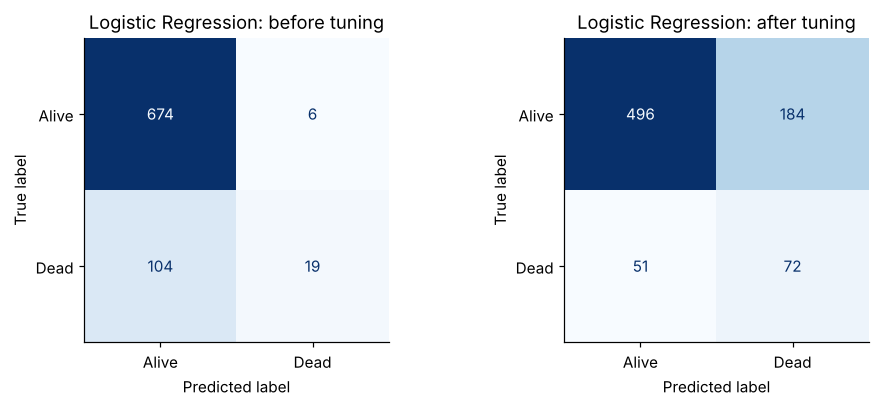

,Model,Precision,F1-score,Recall
0,Before tuning,0.760,0.257,0.154
1,After tuning,0.281,0.380,0.585


In [14]:
# Plotting the test confusion matrix before and after tuning
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, (name, model) in zip(axes, [("Before tuning", lr), ("After tuning", lr_tuned)]):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test), display_labels=["Alive", "Dead"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"Logistic Regression: {name.lower()}")
plt.tight_layout()
plt.savefig("images/lr_before_after_tuning.png", bbox_inches="tight")
plt.show()

# Documenting the used metrics before and after tuning
pd.DataFrame([test_scores("Before tuning", lr), test_scores("After tuning", lr_tuned)])[
    ["Model", "Precision", "F1-score", "Recall"]].round(3)

GridSearchCV chose `C=0.1`, `class_weight="balanced"` and the `liblinear` solver.

After tuning, the F1-score improved from 0.26 to 0.38, which is an increase of almost 50%. The biggest change came from `class_weight="balanced"`: the model now finds 59% of the patients who died (72 out of 123), compared to only 15% (19) before. However, the precision dropped a lot, from 0.76 to 0.28, because the model now predicts a lot more patients as dead and most of these are false alarms.

So the tuning improved the model's ability to find the patients who died, which is the main part of the success criteria, but at the cost of more false alarms. The F1-score shows that overall the balance between the two is better after tuning. Notebook 3 tries to bring the precision back up by combining this model with the pruned decision tree.

## 9. Criticism, limitations and ethical issues

### Criticism of the best model

Even after tuning, Logistic Regression is far from perfect. Around 7 out of 10 of the patients it predicts as dead actually survived, so if it was used in a hospital, a lot of time and resources could be spent on patients who didn't need it. It also still misses 41% of the patients who died. Logistic Regression can also only draw a straight line boundary between the alive and dead patients, so it can't pick up more complex patterns in the data.

### Limitations

- The dataset is imbalanced, with only 15% of the patients dying, which makes it hard for the models to learn what a patient who dies looks like.
- The dataset is missing a lot of information that affects survival, such as the treatment each patient had and any other illnesses. This limits how well any model can do, which is shown by all the ROC-AUC scores being 0.72 or lower.
- The test set only has 123 patients who died, so a small change in which patients end up in it could change the scores quite a bit.
- The dataset needed a lot of cleaning, and there could still be errors in it that look like normal values.

### Ethical issues

- A model like this should only ever be used to support a doctor's decision, never to replace it. If a patient is wrongly predicted to survive they might not get the extra care they need, and if a patient is wrongly predicted to die it could cause them a lot of unnecessary distress.
- Patients and doctors should be able to understand why the model made a prediction. Logistic Regression is easier to explain than the MLP, which is a benefit here.
- The dataset doesn't include ethnicity or income, so I can't check whether the model is fair across different groups of patients.
- Medical data is very sensitive, so it needs to be stored securely and only used for the purpose it was collected for.

## 10. Saving the models for Notebook 3

Notebook 3 combines two of these models in a voting ensemble, so I save them here.

In [15]:
os.makedirs("models", exist_ok=True)
joblib.dump({"Logistic Regression": lr_tuned, "Decision Tree": dt_pruned, "MLP": mlp,
             "features": feature_cols}, "models/classifiers.joblib")
print("Models saved")

Models saved
